In [1]:
import pathlib

import navis.interfaces.neuprint as neu
import numpy as np
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd
from el_hd_plasticity.connectomics.run_epg_instance_distance import get_er_epg_synapses

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_epg_instance_distance
client = cn.npt_client()

## Distance between the synapses of an ER neuron onto EPG neurons of different EB columns

For every synapse of an ER neuron onto an EPG neuron (a presynaptic site on the ER neuron), the cable distance along the ER neuron to the
nearest synapse onto an EPG of a *different EB column*, computed by `python -m el_hd_plasticity.connectomics.run_epg_instance_distance`.
The two EPG instances that innervate the same wedge are treated as one column (`EPG(PB08)_L3` and `EPG(PB08)_R7` are both `L3/R7`),
paired as in [Hulse et al. 2021](https://elifesciences.org/articles/66039/figures#content): R1=L1, R2=L8, R3=L7, R4=L6, R5=L5, R6=L4,
R7=L3, R8=L2. That leaves eight columns rather than sixteen instances, so the nearest different group is never the mirror image of the
synapse's own column. Paths are not length-limited; the histograms use the 0-16 micron scale and bins of the EL distance analyses
(`synapse_distance.ipynb`).


### The EB columns and the color of each

The eight EB columns, their angle around the ring, and the color each is drawn in throughout the notebook,
shown on the full arbors of the EPG neurons themselves (the style of `ring_synapse_visualization.ipynb`).

In [2]:
ebcoords = cn.EBCoordinateSystem()

# EB angle of each EPG column: the phase of the centre of mass of the EB synapses of its EPG neurons. Every
# example below is colored with these, so the hue of a synapse says where around the EB its column sits.
epgs, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='EPG'))
epg_syns = cn.fetch_eb_synapses(ebcoords, epgs['bodyId'].tolist(), side='pre')
epg_syns['type'] = sd.instance_column(epg_syns['bodyId'].map(epgs.set_index('bodyId')['instance']))
column_phase = sd.group_phase(epg_syns)
print(column_phase.sort_values().round(2))

# A cyclic color per column, so that the hue of a synapse says where around the EB its column sits. One
# column is drawn in black instead of its place on the wheel, which both tells it apart from its
# neighbours in the zoomed section below and keeps the ring neurons' magenta to the ring neurons:
# L5/R5 sits where the wheel passes through that magenta, so its synapses would otherwise all but
# vanish on the neuron. Set BLACK_COLUMN to another column to black that one instead.
BLACK_COLUMN = 'L5/R5'
phase_color = plotting.phase_colormap()
column_color = {column: phase_color(phase) for column, phase in column_phase.sort_values().items()}
column_color[BLACK_COLUMN] = 'black'

ers, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ER4d'))
example_er4d = ers['bodyId'].iloc[3]
er4d_skeleton = ebcoords.fetch_skeleton(example_er4d)

syns, _ = get_er_epg_synapses('ER4d')
syns = cn.add_eb_coords(syns.loc[syns['bodyId_pre'] == example_er4d].copy(), ebcoords, type='pre')

print(syns['type'].value_counts().to_dict())

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:266: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


  0%|          | 0/5 [00:00<?, ?it/s]

type
L3/R7   -2.98
L2/R8   -2.24
L1/R1   -1.35
L8/R2   -0.59
L7/R3    0.16
L6/R4    0.93
L5/R5    1.75
L4/R6    2.57
dtype: float64


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

... (22 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'L8/R2': 56, 'L1/R1': 54, 'L3/R7': 48, 'L6/R4': 46, 'L2/R8': 46, 'L7/R3': 44, 'L4/R6': 40, 'L5/R5': 30}


46 of 46 EPG neurons have an EB column


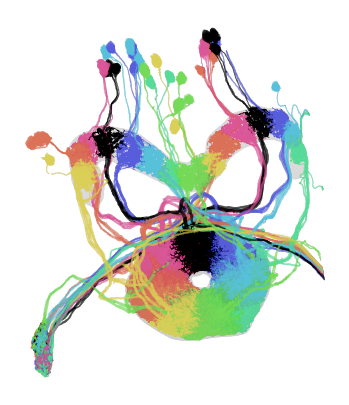

In [11]:
eb, pb = ebcoords.fetch_roi('EB'), ebcoords.fetch_roi('PB')
epg_columns = sd.instance_column(epgs['instance'])
print(f'{sum(column in column_color for column in epg_columns)} of {len(epgs)} EPG neurons have an EB column')

fig, ax = plotting.plot_neurons_2d([eb, pb], colors=plt.cm.Greys(.3), alpha=.9, radius=False)
for body_id, column in zip(epgs['bodyId'], epg_columns, strict=True):
    if column in column_color:
        plotting.plot_neurons_2d([ebcoords.fetch_skeleton(body_id)], colors=column_color[column],
                                 alpha=.5, ax=ax)
# one legend entry per column rather than the one per neuron navis would otherwise add
keys = [ax.plot([], [], color=color, linewidth=3, label=column)[0] for column, color in column_color.items()]
# ax.legend(handles=keys, loc='upper left', bbox_to_anchor=(1., 1.), frameon=False)
fig.savefig(figfolder / 'epg_column_arbors.png', dpi=500, transparent=True, bbox_inches='tight')

### Example ER4d neuron

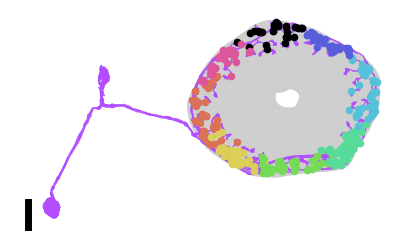

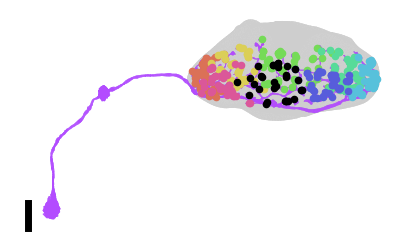

In [10]:
for plane in ('xy', 'xz'):
    fig, ax = plotting.plot_grouped_synapses(er4d_skeleton, syns, column_color, 
                                            view=tuple(plane), linewidth=1.5, items=(eb,),
                                            legend=False)
    fig.savefig(figfolder / f'er4d_epg_column_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')

### Zoomed section of the example ER4d axon

The same stretch of axon, at the same limits and depth shading, as the EL input panel of `synapse_distance.ipynb`.
Only the synapses inside the shaded slab are drawn, so every dot sits on a branch that is visible in the view.
Synapses onto the two EB columns left in this section alternate along a few microns of cable.

In [5]:
syns.head()

,bodyId_pre,bodyId_post,roi_pre,roi_post,x_pre,y_pre,z_pre,x_post,y_post,z_post,...,phase,radius,radius_scaled,xsec_phase,xsec_radius,xsec_radius_scaled,xsec_x,xsec_y,xsec_x_scaled,xsec_y_scaled
1229,1167295916,696362840,EB,EB,26974,25616,17032,26947,25619,17024,...,1.416894,3204.157531,0.833257,-0.941342,1344.725422,1.035540,791.644544,-1087.007533,0.609626,-0.837078
1230,1167295916,696362840,EB,EB,26562,25750,16925,26566,25754,16905,...,1.549034,3152.966878,0.812378,-1.301630,1610.218865,1.046044,428.201306,-1552.239812,0.278172,-1.008379
1231,1167295916,696362840,EB,EB,26667,25713,16938,26684,25715,16938,...,1.515955,3174.703724,0.824525,-1.039619,1371.124842,1.069295,694.541597,-1182.199350,0.541650,-0.921958
1232,1167295916,696362840,EB,EB,27202,24548,16986,27205,24534,16957,...,1.380973,3708.125635,0.955396,-0.369977,1128.667034,0.910119,1052.296616,-408.118984,0.848536,-0.329093
1233,1167295916,696362840,EB,EB,27364,25037,16846,27369,25024,16856,...,1.341828,3708.208106,0.955297,-0.543393,1301.191458,1.036759,1113.766593,-672.772760,0.887423,-0.536050


xy drawn: {'L8/R2': 56, 'L1/R1': 54, 'L3/R7': 48, 'L6/R4': 46, 'L2/R8': 46, 'L7/R3': 44, 'L4/R6': 40, 'L5/R5': 30}


xz drawn: {'L6/R4': 46, 'L4/R6': 40, 'L5/R5': 30, 'L7/R3': 27, 'L3/R7': 11}


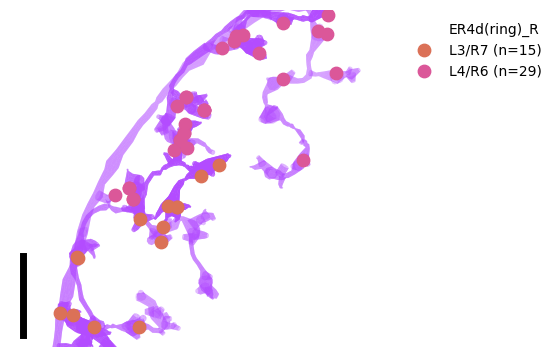

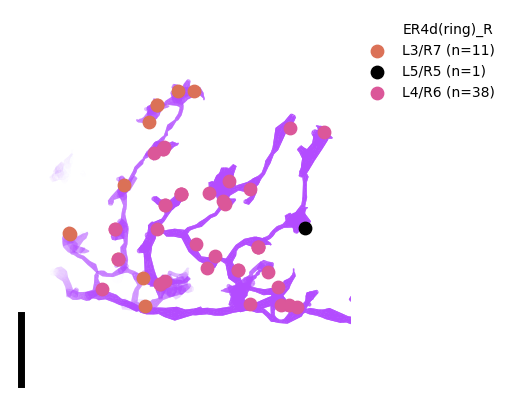

In [6]:
views = {  # plane: the axis the neuron is shaded by, the range of that axis, and the limits of the second axis
    'xy': dict(shade_by='z', smin=-2000, smax=700, ylim=[-300, 2400]),
    'xz': dict(shade_by='y', smin=5, smax=1800, ylim=[-2000, 1500]),
}
XLIM = [-5100, -2000]

for plane, v in views.items():
    # only the synapses inside the slab the neuron is shaded by, so every dot sits on a branch of the view
    depth = syns[f"{v['shade_by']}_eb"]
    filtered_syns = syns[(depth >= v['smin'])] #& (depth <= v['smax'])]
    print(plane, 'drawn:', filtered_syns['type'].value_counts().to_dict())
    fig, ax = plotting.plot_grouped_synapses(
        er4d_skeleton, filtered_syns, column_color, view=tuple(plane), s=80, bar_um=5,
        xlim=XLIM, ylim=v['ylim'], shade_by=v['shade_by'], smin=v['smin'], smax=v['smax'])
    fig.savefig(figfolder / f'er4d_epg_column_synapses_zoom_{plane}.png', dpi=500, transparent=True,
                bbox_inches='tight')

### Example neurons of the other ER types

One neuron per type, whole, with every one of its EPG output synapses colored by the EB column it targets.
A neuron that uses the whole palette spreads its output around the ring; one that uses two or three colors
keeps to a few neighbouring columns.

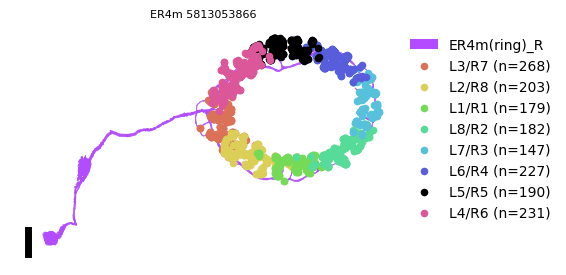

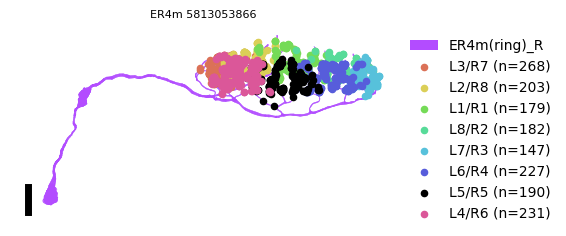

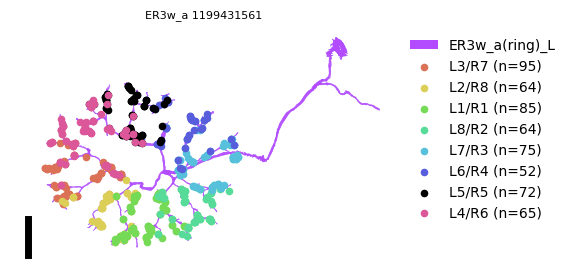

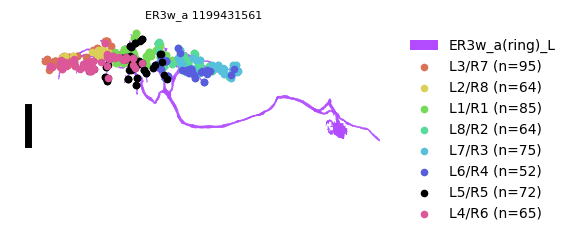

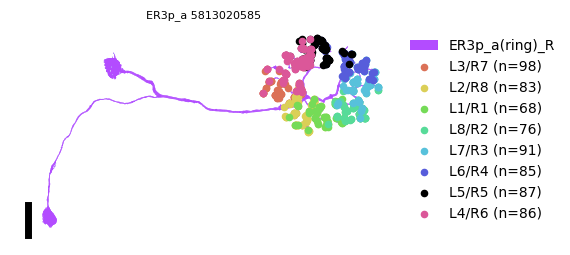

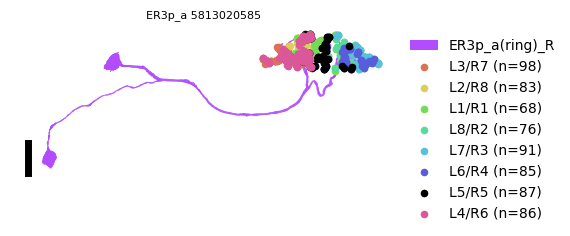

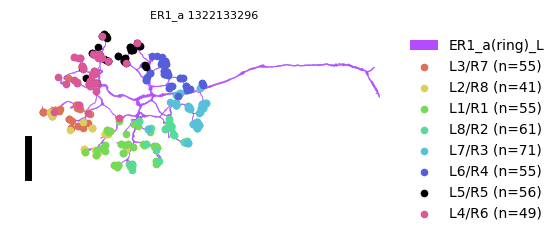

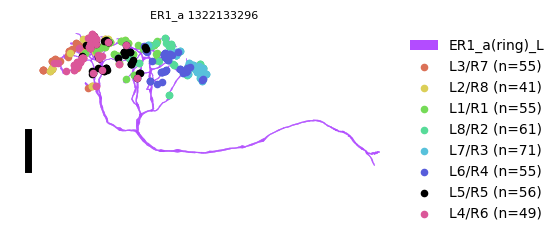

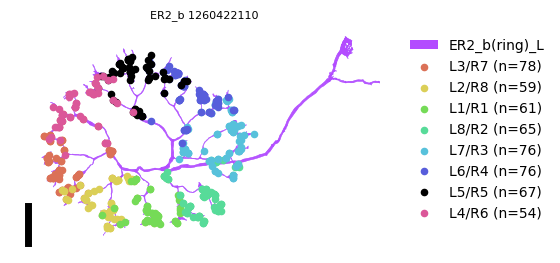

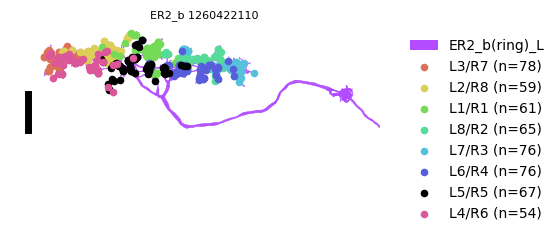

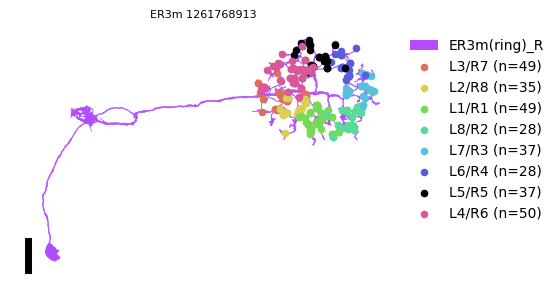

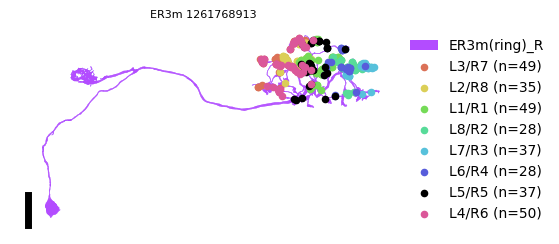

In [7]:
for er_type in ('ER4m', 'ER3w_a', 'ER3p_a', 'ER1_a', 'ER2_b', 'ER3m'):
    er_syns, _ = get_er_epg_synapses(er_type)
    body_id = er_syns['bodyId_pre'].value_counts().index[0]            # the neuron with most synapses
    er_syns = cn.add_eb_coords(er_syns.loc[er_syns['bodyId_pre'] == body_id].copy(), ebcoords, type='pre')
    skeleton = ebcoords.fetch_skeleton(body_id)
    for plane in ('xy', 'xz'):
        fig, ax = plotting.plot_grouped_synapses(skeleton, er_syns, column_color, view=tuple(plane))
        ax.set_title(f'{er_type} {body_id}', fontsize=8)
        fig.savefig(figfolder / f'{er_type}_epg_column_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')

### Distances

In [8]:
distance_df = sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES)
summary = distance_df.groupby('er')['distances'].agg(
    synapses='size', columns=lambda d: distance_df.loc[d.index, 'group'].nunique(),
    fraction_with_a_partner=lambda d: d.notna().mean(), median_microns='median').round(2)
print(summary.loc[list(sd.ER_TYPES)])


        synapses  columns  fraction_with_a_partner  median_microns
er                                                                
ER4d       10000        8                      1.0           13.62
ER4m       14903        8                      1.0            2.86
ER2_a       5091        8                      1.0            6.70
ER2_b       3073        8                      1.0            3.12
ER2_c      12671        8                      1.0            8.01
ER2_d       3249        8                      1.0            5.65
ER3w_b      5874        8                      1.0            1.18
ER3a_c       595        8                      1.0            3.99
ER3p_a      7053        8                      1.0            0.92
ER3w_a      4723        8                      1.0            1.72
ER3a_b        74        8                      1.0           27.74
ER3p_b      2532        8                      1.0            1.61
ER3d_c      2494        8                      1.0            

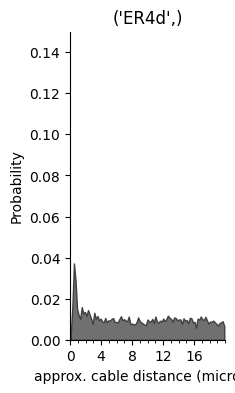

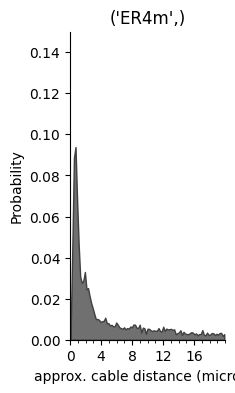

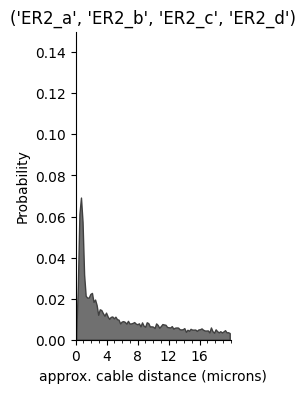

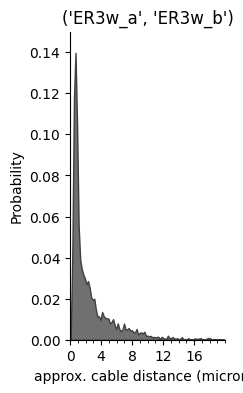

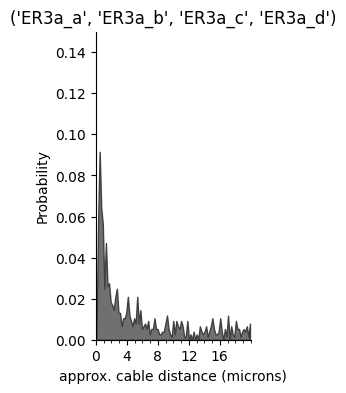

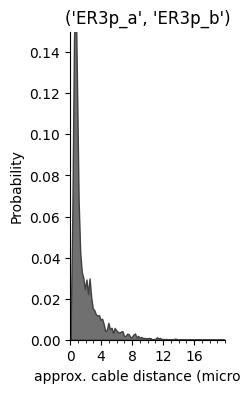

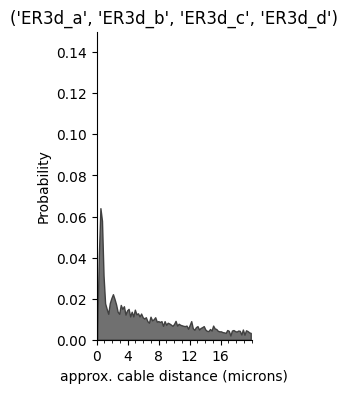

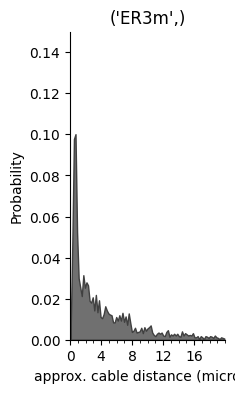

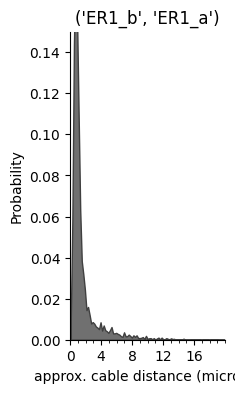

In [9]:
import numpy as np

bins = np.linspace(0,20,100)
xlims = [0,20]
for i, group in enumerate(sd.ER_GROUPS):

    fig, ax = plotting.plot_family_distance_histogram(distance_df, group, bins=bins, xlims=xlims, source='epg_column', color=plt.cm.Greys(.8))
    fig.savefig(figfolder / f'group{i}_epg_column_dist.pdf')


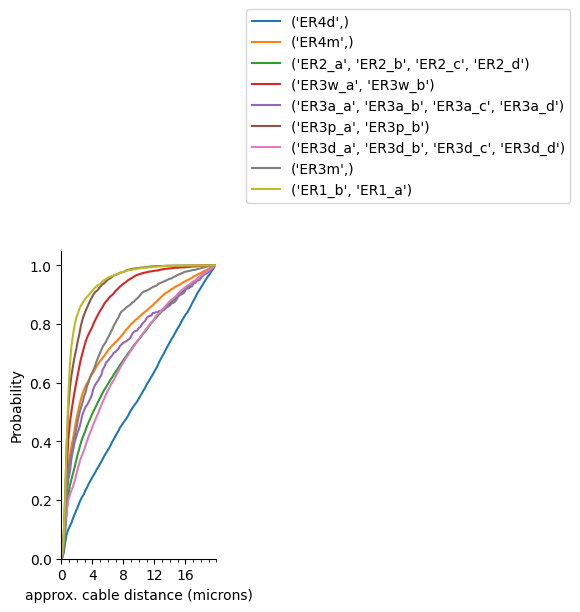

In [10]:
fig, axs = plotting.plot_cumulative_distances(distance_df, sd.ER_GROUPS, bins=bins, xlims=[0,20], sources=('epg_column',), figsize=(2, 4))
fig.savefig(figfolder / 'all_epg_column_dist_cumulative.pdf', bbox_inches='tight')
